# M3-T02 — Compare two scans of the same patient over time
**Done when:** the report shows how much the tumor grew or shrank (%) between two dates.

**Idea.** For each patient we take their scans at different timepoints, measure the volume of each tumor region (TC, WT, ET) and compute
`change % = (V_later − V_earlier) / V_earlier × 100`.
Volumes are measured twice, so the method can be checked:
1. from the **expert masks** (the reference), and
2. from **nnU-Net predictions** (the Milestone 2 model, `seg-model v1`) on the same scans.

**Data:** RHUH-GBM — 40 patients × 3 timepoints (0 = pre-operative, 1 = early post-operative, 2 = recurrence), expert masks at every timepoint.
Pairs compared: 0→1 (what the surgery removed), 1→2 (regrowth), 0→2 (overall).

**Volume rule** (same as M3-T01): voxels × voxel volume from the NIfTI header, in cm³. Regions follow the team's `REGIONS`:
TC = labels 1+3, WT = 1+2+3, ET = 3 (they overlap).

**Run:** Runtime → Change runtime type → **GPU**, fill the config cell, Run all.

## 0. Config

In [1]:
REPO_URL = "https://github.com/nhahub/NHA-5-187.git"
BRANCH   = "main"

BASE          = "/content/drive/MyDrive/BrainMRI_Data"
MODEL_RESULTS = f"{BASE}/runs/M2-T04_nnunet/nnUNet_results"     # folder that contains Dataset501_BraTS2021
WORK_DIR      = f"{BASE}/runs/M3-T02_longitudinal"               # outputs are saved here
LOCAL         = "/content/m3t02"

PATIENTS = None                          # None = every patient found in the cleaned data; or a list like ["RHUH-0001", "RHUH-0002"]
REPORT_PATIENTS = 3                      # how many patients get their own table in the report (all are in the CSV and the cohort summary)
PAIRS    = [(0, 1), (1, 2), (0, 2)]      # (earlier timepoint, later timepoint)
TP_NAMES = {0: "pre-op", 1: "early post-op", 2: "recurrence"}
MIN_VOL_CM3 = 0.1                        # if the first scan has less than this, the % change is not computed (n/a)

# Cleaned scans (same cleaning as the training data): <root>/<subject>/<timepoint>/{t1,t1ce,t2,flair,seg}.nii.gz
# The timepoint folders are named 0.0, 1.0, 2.0 on Drive.
SCAN_ROOTS = [f"{BASE}/processed/rhuh", "/content/processed/rhuh"]
ALLOW_RAW  = False                       # True = fall back to raw RHUH files if the cleaned ones are missing (less reliable)
RAW_SEARCH_ROOT = BASE

# Days between scans, if you have them (from the dataset's clinical CSV). Example: {("RHUH-0001", (0, 1)): 6}
# Leave empty and the report says "interval not stated" (the % change does not need it).
CLINICAL_CSV = f"{BASE}/raw/longitudinal_rhuh_gbm/clinical_data_TCIA_RHUH-GBM.csv"
DAYS_BETWEEN = {}    # filled from the clinical file in section 4b for pre-op -> early post-op (or set your own)

## 1. Drive, repo, packages

In [2]:
from google.colab import drive
drive.mount("/content/drive")

import os, sys, glob, json, subprocess
from pathlib import Path
import numpy as np, pandas as pd, nibabel as nib

os.makedirs(WORK_DIR, exist_ok=True); os.makedirs(LOCAL, exist_ok=True)
if not Path("/content/repo/.git").exists():
    !git clone -q -b {BRANCH} {REPO_URL} /content/repo
!git -C /content/repo log --oneline -1
!pip -q install nibabel "nnunetv2==2.8.1"
sys.path.insert(0, "/content/repo/src")

try:
    from bmts.common.constants import REGIONS
except Exception as e:
    print("could not import REGIONS from the repo (", e, ") - using the same definition by hand")
    REGIONS = {"TC": (1, 3), "WT": (1, 2, 3), "ET": (3,)}
print("REGIONS:", REGIONS)

import torch
print("CUDA:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU")

Mounted at /content/drive
b119cdb (HEAD -> main, origin/main, origin/HEAD) Merge branch M3-T04-uncertainty-map: confidence-map results
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 291.1/291.1 kB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.8/106.8 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.6/53.6 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.4/28.4 MB 79.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 92.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 120.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━

## 2. Find the scans
Uses the **cleaned** scans in `processed/rhuh` (same cleaning as the training data). Patients that miss a timepoint are skipped and listed.

In [3]:
MODS = ["t1", "t1ce", "t2", "flair"]                 # nnU-Net channel order 0..3
_raw_index = {}

def raw_index():
    if not _raw_index:
        print("indexing raw RHUH files under", RAW_SEARCH_ROOT, "(one time) ...")
        for f in glob.glob(f"{RAW_SEARCH_ROOT}/**/RHUH-*.nii.gz", recursive=True):
            _raw_index[Path(f).name] = f
        print(len(_raw_index), "files")
    return _raw_index

def list_subjects():
    subs = set()
    for root in SCAN_ROOTS:
        subs |= {p.name for p in Path(root).glob("RHUH-*") if p.is_dir()}
    if not subs and ALLOW_RAW:
        subs = {n.split("_")[0] for n in raw_index() if n.endswith("_0_t1.nii.gz")}
    return sorted(subs)

def find_scan(subj, tp):
    for root in SCAN_ROOTS:
        for name in (f"{float(tp)}", str(tp), f"tp{tp:02d}"):          # 0.0 | 0 | tp00
            d = Path(root) / subj / name
            if (d / "t1.nii.gz").exists():
                files = {m: str(d / f"{m}.nii.gz") for m in MODS}
                files["seg"] = str(d / "seg.nii.gz"); files["kind"] = "cleaned"
                for k in (*MODS, "seg"):
                    if not os.path.exists(files[k]): raise FileNotFoundError(files[k])
                return files
    if not ALLOW_RAW:
        raise FileNotFoundError(f"{subj} timepoint {tp}: no cleaned scan in {SCAN_ROOTS}")
    idx = raw_index()
    files = {}
    for m in MODS:
        if f"{subj}_{tp}_{m}.nii.gz" not in idx: raise FileNotFoundError(f"{subj} tp{tp} {m}")
        files[m] = idx[f"{subj}_{tp}_{m}.nii.gz"]
    segs = [v for k, v in idx.items() if k.startswith(f"{subj}_{tp}_segmentation")]
    if not segs: raise FileNotFoundError(f"{subj} tp{tp} expert mask")
    files["seg"] = segs[0]; files["kind"] = "raw"
    return files

wanted = list_subjects() if PATIENTS is None else list(PATIENTS)
tps = sorted({t for p in PAIRS for t in p})
SCANS, skipped = {}, {}
for s in wanted:
    try:
        got = {(s, tp): find_scan(s, tp) for tp in tps}
        SCANS.update(got)
    except FileNotFoundError as e:
        skipped[s] = str(e)[:90]
PATIENTS = [s for s in wanted if s not in skipped]
print(len(PATIENTS), "patients ready;", len(skipped), "skipped")
for s, why in skipped.items(): print("  skipped", s, "-", why)
kinds = {v["kind"] for v in SCANS.values()}
print("scan source:", kinds, "| first patients:", PATIENTS[:5])
assert PATIENTS, "no patient with all timepoints found - check SCAN_ROOTS"
if "raw" in kinds:
    print("WARNING: raw RHUH scans are used. The model expects scans cleaned like the M1-T04 data; predictions may be less reliable.")

27 patients ready; 7 skipped
  skipped RHUH-0001 - RHUH-0001 timepoint 0: no cleaned scan in ['/content/drive/MyDrive/BrainMRI_Data/processed
  skipped RHUH-0010 - RHUH-0010 timepoint 2: no cleaned scan in ['/content/drive/MyDrive/BrainMRI_Data/processed
  skipped RHUH-0014 - /content/drive/MyDrive/BrainMRI_Data/processed/rhuh/RHUH-0014/0.0/t1ce.nii.gz
  skipped RHUH-0018 - RHUH-0018 timepoint 0: no cleaned scan in ['/content/drive/MyDrive/BrainMRI_Data/processed
  skipped RHUH-0024 - RHUH-0024 timepoint 0: no cleaned scan in ['/content/drive/MyDrive/BrainMRI_Data/processed
  skipped RHUH-0025 - /content/drive/MyDrive/BrainMRI_Data/processed/rhuh/RHUH-0025/2.0/t1ce.nii.gz
  skipped RHUH-0029 - RHUH-0029 timepoint 0: no cleaned scan in ['/content/drive/MyDrive/BrainMRI_Data/processed
scan source: {'cleaned'} | first patients: ['RHUH-0002', 'RHUH-0003', 'RHUH-0004', 'RHUH-0005', 'RHUH-0006']


## 3. Volumes from the expert masks (the reference)

In [4]:
def region_volumes(path):
    img = nib.load(path)
    arr = np.asarray(img.dataobj)
    assert arr.max() <= 3, f"{path}: labels above 3 found ({np.unique(arr)}) - label scheme differs from 0-3"
    vox_mm3 = float(np.prod(img.header.get_zooms()[:3]))
    return {r: float(np.isin(arr, REGIONS[r]).sum() * vox_mm3 / 1000.0) for r in REGIONS}

vol_expert = {k: region_volumes(v["seg"]) for k, v in SCANS.items()}
pd.DataFrame([{"patient": k[0], "tp": k[1], **v} for k, v in vol_expert.items()]).round(2)

,patient,tp,TC,WT,ET
0,RHUH-0002,0,1.60,28.66,1.25
1,RHUH-0002,1,0.00,6.64,0.00
2,RHUH-0002,2,4.60,10.49,4.29
3,RHUH-0003,0,15.26,41.43,14.02
4,RHUH-0003,1,0.00,1.05,0.00
...,...,...,...,...,...
76,RHUH-0038,1,0.00,81.82,0.00
77,RHUH-0038,2,1.00,10.96,1.00
78,RHUH-0039,0,44.77,121.82,35.06
79,RHUH-0039,1,0.00,59.81,0.00


## 4. Segment the same scans with nnU-Net (seg-model v1)
Same command as in `models/registry/seg-model/v1/inference_config.yaml`. Input files are `<case>_0000…_0003` = T1, T1ce, T2, FLAIR.

In [5]:
IN_DIR, OUT_DIR = f"{LOCAL}/nnunet_in", f"{WORK_DIR}/pred_nnunet"
os.makedirs(IN_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)
for (s, tp), v in SCANS.items():
    for i, m in enumerate(MODS):
        dst = f"{IN_DIR}/{s}_tp{tp}_{i:04d}.nii.gz"
        if not os.path.lexists(dst):
            os.symlink(v[m], dst)

for k in ("nnUNet_raw", "nnUNet_preprocessed"):
    os.makedirs(f"{LOCAL}/{k}", exist_ok=True); os.environ[k] = f"{LOCAL}/{k}"
os.environ["nnUNet_results"] = MODEL_RESULTS
assert Path(MODEL_RESULTS, "Dataset501_BraTS2021").exists(), "MODEL_RESULTS must contain Dataset501_BraTS2021"

In [ ]:
!nnUNetv2_predict -i {IN_DIR} -o {OUT_DIR} -d 501 -c 3d_fullres -f 0 -tr nnUNetTrainer_50epochs -chk checkpoint_best.pth

In [6]:
vol_nnunet = {}
for (s, tp) in SCANS:
    f = f"{OUT_DIR}/{s}_tp{tp}.nii.gz"
    assert os.path.exists(f), f"missing prediction {f}"
    vol_nnunet[(s, tp)] = region_volumes(f)
print(len(vol_nnunet), "predictions measured")

# Optional cross-check with the M3-T01 code, if it is on this branch
try:
    from bmts.quantitative.volumes import volumes_table
    files = sorted(glob.glob(f"{OUT_DIR}/*.nii.gz"))
    t = volumes_table(files).set_index("case")
    worst = max(abs(t.loc[f"{s}_tp{tp}", f"{r}_cm3"] - vol_nnunet[(s, tp)][r]) for (s, tp) in SCANS for r in REGIONS)
    print("M3-T01 volumes_table agrees with this notebook, largest difference (cm3):", round(float(worst), 6))
except Exception as e:
    print("M3-T01 cross-check skipped:", repr(e)[:120])

81 predictions measured
M3-T01 volumes_table agrees with this notebook, largest difference (cm3): 0.0


## 4b. Clinical file: days between scans and a check of our volumes
`Days from earliest imaging to surgery` gives the gap between the pre-operative scan and surgery. The early post-operative scan was taken within 72 h of surgery,
so for **pre-op -> early post-op** this is the interval (up to 3 days longer). The clinical file has no date of the recurrence scan, so the other intervals stay "not stated".
The same file lists the dataset's own volumes (contrast-enhancing tumor and T2/FLAIR abnormality, before and after surgery), which lets us check our volumes independently.

In [7]:
clin = pd.read_csv(CLINICAL_CSV)
clin.columns = [" ".join(str(c).split()) for c in clin.columns]

def find_col(*words):
    hits = [c for c in clin.columns if all(w.lower() in c.lower() for w in words)]
    assert hits, f"no clinical column containing {words}: {list(clin.columns)}"
    return hits[0]

c_id, c_days = find_col("patient id"), find_col("days from earliest imaging")
c_ce_pre, c_ce_post = find_col("preoperative", "contrast enhancing"), find_col("postoperative", "contrast enhancing")
c_t2_pre, c_t2_post = find_col("preoperative", "t2/flair"), find_col("postoperative", "t2/flair")
clin = clin.set_index(c_id)
num = lambda v: float(pd.to_numeric(v, errors="coerce"))

if not DAYS_BETWEEN:
    for s in PATIENTS:
        if s in clin.index and not pd.isna(num(clin.loc[s, c_days])):
            DAYS_BETWEEN[(s, (0, 1))] = num(clin.loc[s, c_days])
print("intervals filled for", len(DAYS_BETWEEN), "patients (pre-op -> early post-op)")

# Our expert volumes vs the dataset's own clinical volumes:
#   contrast-enhancing tumor = our TC (labels 1+3); T2/FLAIR abnormality = our WT minus TC (label 2)
rows = []
for s in PATIENTS:
    if s not in clin.index: continue
    e0, e1 = vol_expert[(s, 0)], vol_expert[(s, 1)]
    rows.append(dict(patient=s,
                     ce_pre=num(clin.loc[s, c_ce_pre]) - e0["TC"], ce_post=num(clin.loc[s, c_ce_post]) - e1["TC"],
                     t2_pre=num(clin.loc[s, c_t2_pre]) - (e0["WT"] - e0["TC"]), t2_post=num(clin.loc[s, c_t2_post]) - (e1["WT"] - e1["TC"])))
chk = pd.DataFrame(rows).set_index("patient")
print("largest |clinical volume - our volume| over", len(chk), "patients (cm3):")
print(chk.abs().max().round(3).to_string())

intervals filled for 27 patients (pre-op -> early post-op)
largest |clinical volume - our volume| over 27 patients (cm3):
ce_pre     5.402
ce_post    0.096
t2_pre     0.011
t2_post    0.014


## 5. Change between two scans

In [8]:
def pct(a, b):
    return (b - a) / a * 100.0 if a >= MIN_VOL_CM3 else float("nan")

def change_table(vols, source):
    rows = []
    for s in PATIENTS:
        for (a, b) in PAIRS:
            for r in REGIONS:
                va, vb = vols[(s, a)][r], vols[(s, b)][r]
                rows.append(dict(patient=s, source=source, pair=f"{TP_NAMES[a]} -> {TP_NAMES[b]}", tp_a=a, tp_b=b, region=r,
                                 vol_a_cm3=va, vol_b_cm3=vb, change_cm3=vb - va, change_pct=pct(va, vb),
                                 days=DAYS_BETWEEN.get((s, (a, b)), np.nan)))
    return pd.DataFrame(rows)

ch_exp, ch_nn = change_table(vol_expert, "expert"), change_table(vol_nnunet, "nnunet")
keys = ["patient", "pair", "tp_a", "tp_b", "region", "days"]
both = ch_exp.merge(ch_nn, on=keys, suffixes=("_expert", "_nnunet"))
both["pct_diff_points"] = both.change_pct_nnunet - both.change_pct_expert
both.to_csv(f"{WORK_DIR}/tumor_change_long.csv", index=False)
both.round(2)

,patient,source_expert,pair,tp_a,tp_b,region,vol_a_cm3_expert,vol_b_cm3_expert,change_cm3_expert,change_pct_expert,days,source_nnunet,vol_a_cm3_nnunet,vol_b_cm3_nnunet,change_cm3_nnunet,change_pct_nnunet,pct_diff_points
0,RHUH-0002,expert,pre-op -> early post-op,0,1,TC,1.60,0.00,-1.60,-100.00,9.0,nnunet,2.52,28.65,26.13,1038.14,1138.14
1,RHUH-0002,expert,pre-op -> early post-op,0,1,WT,28.66,6.64,-22.02,-76.83,9.0,nnunet,31.71,46.76,15.05,47.44,124.27
2,RHUH-0002,expert,pre-op -> early post-op,0,1,ET,1.25,0.00,-1.25,-100.00,9.0,nnunet,2.12,6.91,4.80,226.55,326.55
3,RHUH-0002,expert,early post-op -> recurrence,1,2,TC,0.00,4.60,4.60,NaN,NaN,nnunet,28.65,9.58,-19.07,-66.56,NaN
4,RHUH-0002,expert,early post-op -> recurrence,1,2,WT,6.64,10.49,3.85,57.97,NaN,nnunet,46.76,22.64,-24.12,-51.59,-109.56
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
238,RHUH-0039,expert,early post-op -> recurrence,1,2,WT,59.81,225.51,165.70,277.07,NaN,nnunet,146.64,253.68,107.05,73.00,-204.06
239,RHUH-0039,expert,early post-op -> recurrence,1,2,ET,0.00,50.31,50.31,NaN,NaN,nnunet,4.31,50.12,45.81,1061.89,NaN
240,RHUH-0039,expert,pre-op -> recurrence,0,2,TC,44.77,60.97,16.20,36.19,NaN,nnunet,42.22,80.32,38.10,90.22,54.03
241,RHUH-0039,expert,pre-op -> recurrence,0,2,WT,121.82,225.51,103.69,85.12,NaN,nnunet,120.72,253.68,132.96,110.14,25.02


In [9]:
# How well does the automatic change agree with the expert change? (only where the % is defined for both)
ok = both.dropna(subset=["change_pct_expert", "change_pct_nnunet"])
print(f"{len(ok)} of {len(both)} comparisons have a defined % change in both")
if len(ok):
    summ = ok.assign(abs_diff=ok.pct_diff_points.abs()).groupby("region").abs_diff.agg(["count", "median", "max"]).round(1)
    summ.columns = ["n", "median |difference| (% points)", "max |difference| (% points)"]
    display(summ)
    same_dir = (np.sign(ok.change_pct_expert) == np.sign(ok.change_pct_nnunet)).mean()
    print(f"nnU-Net gets the direction (grew vs shrank) right in {same_dir:.0%} of comparisons")

207 of 243 comparisons have a defined % change in both


,n,median |difference| (% points),max |difference| (% points)
region,,,
ET,63,17.1,17896.9
TC,63,87.8,24366.0
WT,81,52.6,3494.2


nnU-Net gets the direction (grew vs shrank) right in 78% of comparisons


### Agreement tables (used in the report)

In [10]:
tps_all = sorted({t for p in PAIRS for t in p})
rows = []
for tp in tps_all:
    for r in REGIONS:
        e = np.array([vol_expert[(s, tp)][r] for s in PATIENTS]); n = np.array([vol_nnunet[(s, tp)][r] for s in PATIENTS])
        c = np.corrcoef(e, n)[0, 1] if e.std() > 0 and n.std() > 0 else np.nan
        rows.append(dict(timepoint=TP_NAMES[tp], region=r, correlation=c, expert_median_cm3=np.median(e),
                         nnunet_median_cm3=np.median(n), median_abs_error_cm3=np.median(np.abs(n - e))))
vol_agree = pd.DataFrame(rows).round(2)

ok = both.dropna(subset=["change_pct_expert", "change_pct_nnunet"]).copy()
ok["same_direction"] = np.sign(ok.change_pct_expert) == np.sign(ok.change_pct_nnunet)
ok["abs_diff"] = ok.pct_diff_points.abs()
pair_agree = (ok.groupby(["pair", "region"], sort=False)
                .agg(n=("abs_diff", "size"), same_direction=("same_direction", "mean"), median_abs_diff_points=("abs_diff", "median"))
                .round(2).reset_index())
by_pair = ok.groupby("pair", sort=False).agg(n=("abs_diff", "size"), same_direction=("same_direction", "mean"),
                                             median_abs_diff_points=("abs_diff", "median"))

def md_table(df):
    cols = list(df.columns)
    out = ["| " + " | ".join(cols) + " |", "| " + " | ".join("---" for _ in cols) + " |"]
    for _, r in df.iterrows():
        out.append("| " + " | ".join("" if pd.isna(v) else (f"{v:.2f}" if isinstance(v, float) else str(v)) for v in r.values) + " |")
    return "\n".join(out)

display(vol_agree); display(pair_agree); display(by_pair.round(2))

,timepoint,region,correlation,expert_median_cm3,nnunet_median_cm3,median_abs_error_cm3
0,pre-op,TC,1.00,31.18,30.08,0.86
1,pre-op,WT,1.00,99.48,105.83,1.69
2,pre-op,ET,1.00,17.39,16.37,0.78
3,early post-op,TC,0.03,0.00,32.19,32.19
4,early post-op,WT,0.80,24.99,84.15,57.46
5,early post-op,ET,0.36,0.00,2.13,2.13
6,recurrence,TC,0.58,9.66,24.80,1.98
7,recurrence,WT,0.89,44.13,83.06,11.00
8,recurrence,ET,0.54,8.74,11.08,1.49


,pair,region,n,same_direction,median_abs_diff_points
0,pre-op -> early post-op,TC,27,0.44,107.39
1,pre-op -> early post-op,WT,27,0.74,52.61
2,pre-op -> early post-op,ET,27,0.93,14.89
3,early post-op -> recurrence,WT,27,0.70,124.52
4,pre-op -> recurrence,TC,27,0.81,27.41
5,pre-op -> recurrence,WT,27,0.89,14.09
6,pre-op -> recurrence,ET,27,0.93,13.85
7,early post-op -> recurrence,TC,9,0.56,4363.97
8,early post-op -> recurrence,ET,9,1.00,3155.77


,n,same_direction,median_abs_diff_points
pair,,,
pre-op -> early post-op,81,0.70,51.01
early post-op -> recurrence,45,0.73,417.75
pre-op -> recurrence,81,0.88,16.90


## 6. Report

In [11]:
import matplotlib.pyplot as plt

def f_pct(x): return "n/a" if pd.isna(x) else f"{x:+.1f}%"
def f_days(x): return "interval not stated" if pd.isna(x) else f"about {int(x)} day" + ("" if int(x) == 1 else "s")

lines = ["# M3-T02: tumor change between two scans of the same patient", "",
         "Volume change in percent, `(V_later - V_earlier) / V_earlier x 100`, per region. Volumes = voxels x voxel volume (cm3); "
         "regions follow the team's REGIONS (TC = labels 1+3, WT = 1+2+3, ET = 3). "
         "'expert' = volumes from the expert masks (reference); 'nnU-Net' = volumes from seg-model v1 predictions on the same scans.", ""]
for s in PATIENTS[:REPORT_PATIENTS]:
    lines += [f"## {s}", "", "| Interval | Between | Region | Volume before (cm3) | Volume after (cm3) | Change (expert) | Change (nnU-Net) |",
              "| --- | --- | --- | --- | --- | --- | --- |"]
    for _, r in both[both.patient == s].iterrows():
        lines.append(f"| {r.pair} | {f_days(r.days)} | {r.region} | {r.vol_a_cm3_expert:.2f} | {r.vol_b_cm3_expert:.2f} | "
                     f"{f_pct(r.change_pct_expert)} | {f_pct(r.change_pct_nnunet)} |")
    lines.append("")
    wt = both[(both.patient == s) & (both.region == "WT")]
    for _, r in wt.iterrows():
        if pd.isna(r.change_pct_expert):
            lines.append(f"- {r.pair}: whole tumor (WT) change not computed, the first scan has less than {MIN_VOL_CM3} cm3 of WT.")
        else:
            verb = "grew" if r.change_pct_expert > 0 else "shrank"
            lines.append(f"- {r.pair}: the whole tumor (WT) {verb} by {abs(r.change_pct_expert):.1f}% "
                         f"({r.vol_a_cm3_expert:.1f} to {r.vol_b_cm3_expert:.1f} cm3, expert; nnU-Net says {f_pct(r.change_pct_nnunet)}).")
    lines.append("")

best, worst = by_pair.same_direction.idxmax(), by_pair.same_direction.idxmin()
pre = vol_agree[vol_agree.timepoint == TP_NAMES[0]]
lines += ["## How well nnU-Net matches the expert masks", "",
          "Volumes per timepoint (correlation between nnU-Net and expert volumes over the patients, medians in cm3):", "", md_table(vol_agree), "",
          "% change per interval and region (n = patients where the % is defined in both; same_direction = share of patients where nnU-Net gets grew/shrank right; "
          "median_abs_diff_points = median difference in percentage points):", "", md_table(pair_agree), "",
          f"- Best interval for the automatic method: {best} (direction right in {by_pair.loc[best, 'same_direction']:.0%}, median difference {by_pair.loc[best, 'median_abs_diff_points']:.1f} points over all regions).",
          f"- Weakest interval: {worst} (direction right in {by_pair.loc[worst, 'same_direction']:.0%}, median difference {by_pair.loc[worst, 'median_abs_diff_points']:.1f} points).",
          f"- On the pre-operative scans, the kind the model was trained on, nnU-Net and expert volumes correlate at r >= {pre.correlation.min():.2f} (median error up to {pre.median_abs_error_cm3.max():.1f} cm3), so the volume measurement itself is sound.",
          f"- Our expert volumes reproduce the dataset's own clinical volumes (enhancing tumor and T2/FLAIR abnormality, before and after surgery) with a largest difference of {chk.abs().max().max():.2f} cm3 over {len(chk)} patients.", ""]

okb = both.dropna(subset=["change_pct_expert", "change_pct_nnunet"])
if len(okb):
    lines += [f"## All {len(PATIENTS)} patients: median change", "",
              "Median % change per interval and region, over the patients where the percentage is defined for both the expert masks and nnU-Net.", "",
              "| Interval | Region | Patients (n) | Median change (expert) | Median change (nnU-Net) |", "| --- | --- | --- | --- | --- |"]
    for (pair, region), g in okb.groupby(["pair", "region"], sort=False):
        lines.append(f"| {pair} | {region} | {len(g)} | {f_pct(g.change_pct_expert.median())} | {f_pct(g.change_pct_nnunet.median())} |")
    lines.append("")

lines += ["## Notes and limits", "",
          f"- '% n/a' means the region was smaller than {MIN_VOL_CM3} cm3 in the first scan, so a percentage would be meaningless; use the change in cm3 instead.",
          "- The model was trained on pre-treatment BraTS 2021 scans. Post-operative and recurrence scans are outside that range, so the expert-mask numbers are the reference and the nnU-Net numbers are a check on the method.",
          "- RHUH-GBM labels: 1 = necrosis, 2 = peritumoral signal (edema plus non-enhancing tumor), 3 = enhancing tumor. TC (labels 1+3) leaves out non-enhancing tumor, so rely on WT and ET.",
          f"- Patients: RHUH-GBM has 40 patients; {len(PATIENTS)} have all {len(tps)} timepoints in the cleaned data. The others are left out because cleaned scans are missing ({len(skipped)} with incomplete folders, the rest have no cleaned folder).",
          "- Intervals: for pre-op -> early post-op the days are the days from the earliest imaging to surgery in the clinical file (the early post-op scan is within 72 h of surgery, so the real gap can be up to 3 days longer). The clinical file has no recurrence-scan date, so the other intervals are not stated.",
          "- Intervals that include the early post-operative scan agree least, which fits with the model never seeing post-operative scans in training (surgical cavity, blood products). Use the expert-based percentages as the reference and treat the nnU-Net-based ones as an estimate that is only reliable where the tables above say so.",
          "- Early post-operative scans can show surgical changes (cavity, blood products) that no region label describes.",
          f"- Scan source: {', '.join(sorted(kinds))}. Days between scans come from the dataset's clinical data only when given in the config.",
          "- Percent changes of small regions swing widely: a few voxels of difference can look like a large percentage."]
report = "\n".join(lines)
open(f"{WORK_DIR}/report_M3-T02.md", "w").write(report)
print(report[:3500])

# M3-T02: tumor change between two scans of the same patient

Volume change in percent, `(V_later - V_earlier) / V_earlier x 100`, per region. Volumes = voxels x voxel volume (cm3); regions follow the team's REGIONS (TC = labels 1+3, WT = 1+2+3, ET = 3). 'expert' = volumes from the expert masks (reference); 'nnU-Net' = volumes from seg-model v1 predictions on the same scans.

## RHUH-0002

| Interval | Between | Region | Volume before (cm3) | Volume after (cm3) | Change (expert) | Change (nnU-Net) |
| --- | --- | --- | --- | --- | --- | --- |
| pre-op -> early post-op | about 9 days | TC | 1.60 | 0.00 | -100.0% | +1038.1% |
| pre-op -> early post-op | about 9 days | WT | 28.66 | 6.64 | -76.8% | +47.4% |
| pre-op -> early post-op | about 9 days | ET | 1.25 | 0.00 | -100.0% | +226.5% |
| early post-op -> recurrence | interval not stated | TC | 0.00 | 4.60 | n/a | -66.6% |
| early post-op -> recurrence | interval not stated | WT | 6.64 | 10.49 | +58.0% | -51.6% |
| early post-op -> recurr

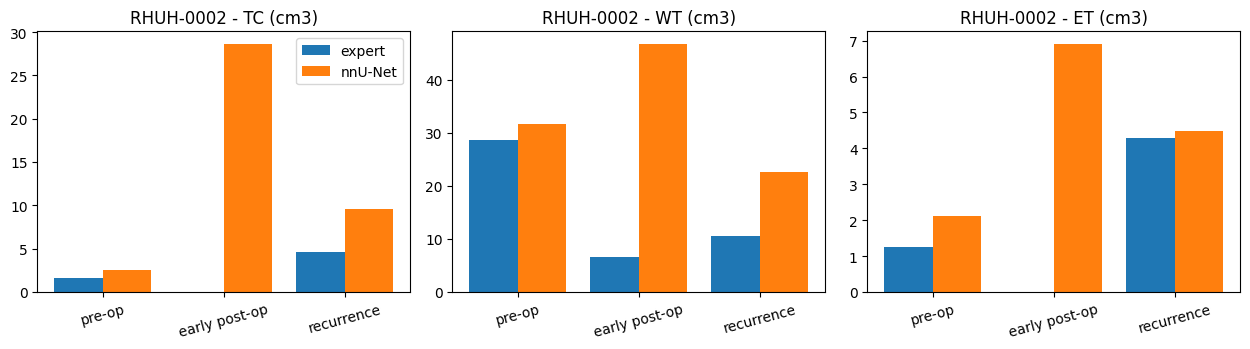

saved to /content/drive/MyDrive/BrainMRI_Data/runs/M3-T02_longitudinal : ['pred_nnunet', 'report_M3-T02.md', 'tumor_change_long.csv', 'volumes_RHUH-0002.png']


In [12]:
# One figure: volumes of every region at every timepoint, expert vs nnU-Net (first patient)
s = PATIENTS[0]
tps = sorted({t for p in PAIRS for t in p})
fig, ax = plt.subplots(1, len(REGIONS), figsize=(4.2 * len(REGIONS), 3.6), sharey=False)
for a, r in zip(np.atleast_1d(ax), REGIONS):
    x = np.arange(len(tps))
    a.bar(x - 0.2, [vol_expert[(s, t)][r] for t in tps], 0.4, label="expert")
    a.bar(x + 0.2, [vol_nnunet[(s, t)][r] for t in tps], 0.4, label="nnU-Net")
    a.set_xticks(x); a.set_xticklabels([TP_NAMES[t] for t in tps], rotation=15)
    a.set_title(f"{s} - {r} (cm3)")
np.atleast_1d(ax)[0].legend()
plt.tight_layout(); plt.savefig(f"{WORK_DIR}/volumes_{s}.png", dpi=150); plt.show()
print("saved to", WORK_DIR, ":", sorted(os.listdir(WORK_DIR)))

## 7. Wrap-up
- [ ] Put this notebook in the repo as `notebooks/07_m3_t02_scan_comparison.ipynb` and the small outputs (`report_M3-T02.md`, `tumor_change_long.csv`, the figure) in `results/M3-T02/`, on a branch for M3-T02, then open a pull request.
- [ ] Notion: paste the WT/ET change table of one patient and the agreement summary; set **Status** and **Completed by**.
- [ ] Tell the owners of "Combine everything into one analysis pipeline" and "Milestone 3 review" that the comparison is ready (the function to reuse is `change_table`, input = volumes per timepoint).
- [ ] Open question for the team: the RHUH clinical file has no recurrence-scan date, so intervals for pairs with the recurrence scan are not stated; check the dataset paper (Cepeda et al., Data in Brief 2023) for how progression-free survival relates to the recurrence scan before using it as an interval.